# Plantillas de clusters: reproducción de Canale (11/16) y O'Keeffe (0.6929)

Dirección A. La idea del "stackeo" (`notes/idea.md`) lleva al marco de **plantillas** $(x, \varphi, P)$:
- $x_a$: fracción de osciladores en el cluster $a$;
- $\varphi_a$: fase común del cluster;
- $P_{ab} \in [0,1]$: densidad de links entre clusters.

Es el marco de O'Keeffe (arXiv 2610.21271, oct. 2026), que con él prueba $\mu_c \ge 0.6929$.
En este notebook:
1. verificamos el lema del blow-up;
2. reproducimos C4, los twisted states, Canale y S7;
3. certificamos S7 con un código propio (Krawczyk + Cholesky por intervalos);
4. mostramos la exploración de otros patrones de partición.

Condiciones de una plantilla **estricta** (O'Keeffe, sec. III), en el límite de red grande:

| | fórmula | condición |
|---|---|---|
| grado | $d_a = \sum_b P_{ab} x_b$ | $\mu(T) = \min_a d_a$ |
| equilibrio | $F_a = \sum_b P_{ab} x_b \sin(\varphi_a - \varphi_b)$ | $= 0$ |
| splitting | $c_a = \sum_b P_{ab} x_b \cos(\varphi_a - \varphi_b)$ | $> 0$ |
| modos de cluster | $L(y) = \sum_{a<b} x_a x_b P_{ab}\cos(\varphi_a-\varphi_b)(y_a-y_b)^2$ | $> 0$ fuera de $y \propto \mathbf 1$ |

El código está en `src/` (`kuramoto.py` es una copia de las funciones de `Calentamientos.ipynb`).

In [1]:
import sys, json, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import mpmath as mp
from scipy.optimize import linprog

from src.kuramoto import classify, simulate, circulant_graph, twisted_state, hessian
from src.templates import Template, c4_template, canale_template, realize
from src import s7
from src.certify import rationalize, newton_phases, certify

plt.rcParams["figure.dpi"] = 110

## 1. El lema del blow-up

En $G[K_m]$ cada vértice pasa a ser un clique de $m$ copias, y cada copia se une con todas las
copias de los vecinos. Entonces $\mu$ queda **igual** y la trampa sobrevive. En cambio, en el
producto cartesiano $G \,\square\, K_m$ (solo cliques entre copias) $\mu$ baja.

Ejemplo: la trampa $q = 1$ de $C_{20,6}$.

In [2]:
n, k = 20, 6
W, th = circulant_graph(n, k), twisted_state(n, 1)
mu = lambda W: (W.sum(1).min() + 1) / len(W)
print(f"{'m':>2} {'producto':>12} {'μ':>7} {'clasificación':>16} {'λ_2':>7}")
for m in [1, 2, 3, 4]:
    J, I = np.ones((m, m)), np.eye(m)
    for name, M in [("cartesiano", np.kron(I, W) + np.kron(J - I, np.eye(n))),
                    ("lexicográf.", np.kron(J, W) + np.kron(J - I, np.eye(n)))]:
        lab, eig = classify(np.tile(th, m), M)
        print(f"{m:>2} {name:>12} {mu(M):7.4f} {lab:>16} {np.sort(eig)[1]:7.3f}")

 m     producto       μ    clasificación     λ_2
 1   cartesiano  0.6500  mínimo estricto   0.505
 1  lexicográf.  0.6500  mínimo estricto   0.505
 2   cartesiano  0.3500  mínimo estricto   0.505
 2  lexicográf.  0.6500  mínimo estricto   1.009
 3   cartesiano  0.2500  mínimo estricto   0.505
 3  lexicográf.  0.6500  mínimo estricto   1.514
 4   cartesiano  0.2000  mínimo estricto   0.505
 4  lexicográf.  0.6500  mínimo estricto   2.019


## 2. El estado de 4 clusters C4 ($\mu = 3/4$)

Cuatro clusters iguales en los cuartos de vuelta, cada uno unido a sí mismo y a sus dos vecinos.
Los vecinos están a $\pi/2$, así que $\cos = 0$ y **$L \equiv 0$**: el estado es degenerado. Lepsveridze–Zhang
prueban que no es un mínimo (lo destruyen términos cúbicos).

In [3]:
T = c4_template()
print({k: round(float(v), 12) for k, v in T.report().items()})
print("autovalores de L en ⊥1:", np.round(T.cluster_eigs(), 14))

{'mu': 0.75, 'max|F|': 0.0, 'min c': 0.25, 'min eig L': -0.0}
autovalores de L en ⊥1: [-0.  0.  0.]


## 3. Twisted states como plantilla: un LP

$m$ clusters iguales en $\varphi_a = 2\pi q a/m$, con densidad $p_j$ que depende solo de la distancia
$j$. Por simetría el equilibrio es automático, y los autovalores de $L$ son lineales en $p$:
maximizar el grado es un **LP**. Se excluye $q = m/4$, que es C4 (degenerado).

mejor: m = 19, μ = 0.683876   (Yoneda–Tatsukawa–Teramae 2021: 0.6838)
m = 120: μ = 0.681966   (límite de C_(n,k) con q = 1: ≈ 0.681)


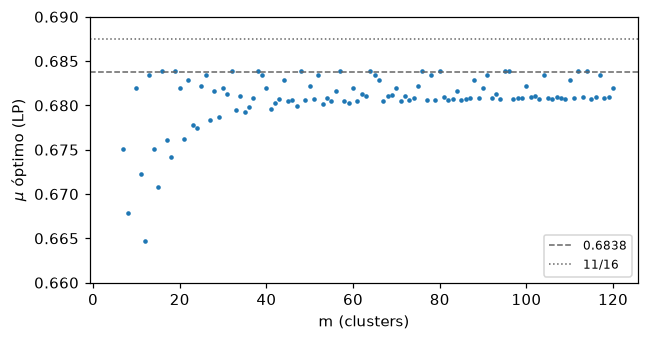

In [4]:
def twisted_lp(m, q=1, eps=1e-9):
    J = np.arange(1, m // 2 + 1)
    mult = np.where((m % 2 == 0) & (J == m // 2), 1, 2)
    d = 2 * np.pi * q / m
    A = [-mult * np.cos(J * d) * (2 - 2 * np.cos(2 * np.pi * J * k / m)) / m**2 for k in range(1, m)]
    b = [-eps] * (m - 1)
    A.append(-mult * np.cos(J * d) / m); b.append(1 / m - eps)
    res = linprog(-mult / m, A_ub=A, b_ub=b, bounds=[(0, 1)] * len(J), method="highs")
    return (1 / m - res.fun) if res.success else 0.0

ms = np.arange(5, 121)
best = np.array([max(twisted_lp(m, q) for q in range(1, (m - 1) // 4 + 1) if 4 * q != m) for m in ms])
i = best.argmax()
print(f"mejor: m = {ms[i]}, μ = {best[i]:.6f}   (Yoneda–Tatsukawa–Teramae 2021: 0.6838)")
print(f"m = 120: μ = {best[-1]:.6f}   (límite de C_(n,k) con q = 1: ≈ 0.681)")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(ms, best, ".", ms=4)
for y, lab, ls in [(0.6838, "0.6838", "--"), (11 / 16, "11/16", ":")]:
    ax.axhline(y, ls=ls, color="0.4", lw=1, label=lab)
ax.set(xlabel="m (clusters)", ylabel=r"$\mu$ óptimo (LP)", ylim=(0.66, 0.69))
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4. Canale (11/16)

Grafo ponderado $G_p$ con 8 vértices: 4 pares de clusters, uno por cuarto de vuelta, en
$\pi i/2 \pm \beta/2$. Los conjuntos de índices $E_t$ del paper tienen erratas, así que usamos la
geometría de su Fig. 2 y del Hessiano del Lema 1. Cada tipo de arista tiene una diferencia de fase:

| tipo | diferencia | quiénes |
|---|---|---|
| c | $\beta$ | dentro del par |
| a | $\alpha$ | miembros cercanos de pares vecinos |
| b | $\pi/2$ | mismo lado (se compensan) |
| d | $\alpha + 2\beta$ | miembros lejanos |

Equilibrio: $(a-d)\tan\alpha = c$. **Lema 1:** es estable si $c^2 > 2ad$. Con $a=b=c=1$ y
$d \to 1/2^-$ queda $\mu \to 5.5/8 = 11/16$.

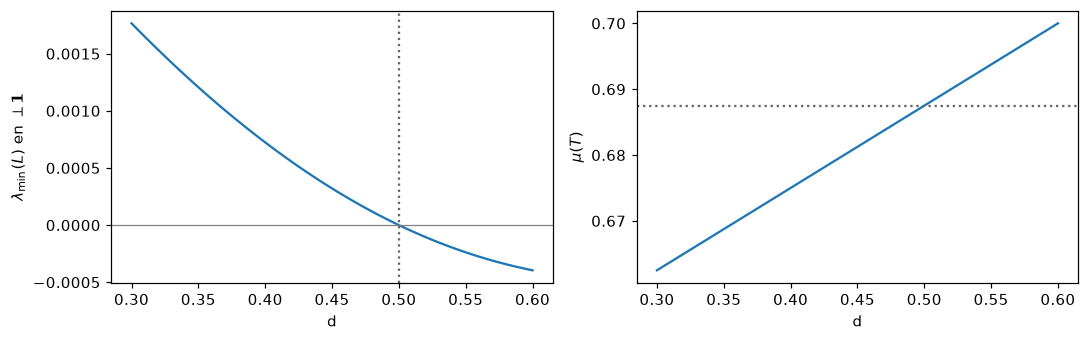

In [5]:
ds = np.linspace(0.3, 0.6, 61)
lam = [canale_template(d=d).cluster_eigs().min() for d in ds]
mus = [canale_template(d=d).mu() for d in ds]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(ds, lam); ax[0].axhline(0, color="0.5", lw=0.8); ax[0].axvline(0.5, ls=":", color="0.4")
ax[0].set(xlabel="d", ylabel=r"$\lambda_{\min}(L)$ en $\perp\mathbf{1}$")
ax[1].plot(ds, mus); ax[1].axhline(11 / 16, ls=":", color="0.4")
ax[1].set(xlabel="d", ylabel=r"$\mu(T)$")
plt.tight_layout(); plt.show()

**Grafos reales.** El $k$-spinning $S_k(G_{p_k})$ con $p_k = (k, k, k, \lceil k/2\rceil - 1)$ es nuestro
`realize` con anillos $\mathbb Z_k$. Chequeamos con el Hessiano del grafo completo y con una
simulación desde un estado perturbado.

In [6]:
print(f"{'k':>3} {'n':>4} {'δ':>4} {'δ/(n−1)':>8} {'clasificación':>16} {'λ_2':>7}")
for k in [4, 8, 12, 16, 20]:
    d = int(np.ceil(k / 2)) - 1
    W, th = realize(canale_template(d=d / k), k, rng=0, kind="interval")
    lab, eig = classify(th, W)
    print(f"{k:>3} {len(W):>4} {W.sum(1).min():>4.0f} {W.sum(1).min() / (len(W) - 1):8.4f} {lab:>16} {np.sort(eig)[1]:7.3f}")

W, th = realize(canale_template(d=3 / 8), 8, rng=0, kind="interval")
sim = simulate(th + 0.05 * np.random.default_rng(1).standard_normal(len(th)), W, record=False)
dev = np.angle(np.exp(1j * (sim["theta"] - th)))
print(f"\nsimulación (k = 8) desde una perturbación de 0.05: vuelve al estado salvo rotación, dispersión {np.ptp(dev):.1e}")

  k    n    δ  δ/(n−1)    clasificación     λ_2
  4   32   20   0.6452  mínimo estricto   0.614
  8   64   42   0.6667  mínimo estricto   0.489
 12   96   64   0.6737  mínimo estricto   0.446
 16  128   86   0.6772  mínimo estricto   0.424
 20  160  108   0.6792  mínimo estricto   0.411



simulación (k = 8) desde una perturbación de 0.05: vuelve al estado salvo rotación, dispersión 7.0e-11


## 5. S7 de O'Keeffe (0.6929)

**Modelo límite.** $q^*$ y $w^*$ resuelven las dos condiciones de neutralidad $f = e = 0$
(Apéndice A) y $\mu_0 = (4+2q^*)/(7+q^*)$.

In [7]:
mp.mp.dps = 40
q, w, mu0 = s7.corner()
print("q* =", mp.nstr(q, 20), "   w* =", mp.nstr(w, 20), "   μ0 =", mp.nstr(mu0, 20))
print("polinomio (3) en q*:", mp.nstr(s7.poly3(q), 3))

q* = 0.65056916694479880261    w* = 1.3982781340204611796    μ0 = 0.69290770636958636365
polinomio (3) en q*: 1.47e-39


**Miembros finitos.** $P = p + h\,p' + \Delta$, con $\Delta = O(h^2)$ sobre el camino
Am–Bm–Cm–W–Cp–Bp–Ap, elegido para que el equilibrio sea exacto. Primero verificamos que
$F(p + hp') = O(h^2)$, lo que confirma que leímos bien el $p'$ del paper. Después miramos $\mu$ y la
brecha de $L$ para varios $(t, h)$; con $t < 0$ (o sea $q > q^*$) tiene que fallar.

In [8]:
for h in ["1e-2", "1e-3", "1e-4"]:
    S = s7.build("1e-3", h, solve_delta=False)
    print(f"h = {h}:  max|F(p + h p')| = {mp.nstr(max(abs(v) for v in S['F_first']), 3)}")
print()
print(f"{'t':>7} {'h':>6} {'μ':>13} {'λ_2 (M)':>10} {'estricta':>9}")
for t, h in [("0.01", "1e-3"), ("1e-3", "1e-4"), ("1e-5", "1e-6"), ("-0.01", "1e-4")]:
    r = s7.analyze(s7.build(t, h))
    print(f"{t:>7} {h:>6} {mp.nstr(r['mu'], 11):>13} {mp.nstr(r['eig'][1], 3):>10} {str(r['eig'][1] > 0):>9}")

h = 1e-2:  max|F(p + h p')| = 1.45e-5
h = 1e-3:  max|F(p + h p')| = 1.47e-7
h = 1e-4:  max|F(p + h p')| = 1.47e-9

      t      h             μ    λ_2 (M)  estricta
   0.01   1e-3 0.69022172846    1.31e-8      True
   1e-3   1e-4 0.69263949191   1.32e-11      True
   1e-5   1e-6 0.69290502465   1.32e-17      True
  -0.01   1e-4 0.69451686914  -1.13e-10     False


**Certificado propio** (`src/certify.py`, `scripts/certify_s7.py`). Los pasos son:
1. redondear $(x, P)$ a racionales con denominador $D$;
2. refinar las fases por Newton;
3. **Krawczyk** con `mpmath.iv` para la existencia y unicidad del equilibrio en una caja de radio
   $\sim 10^{-54}$;
4. **Cholesky por intervalos** de $L$ sin la fila 1, para ver que $L \succ 0$ fuera de la rotación;
5. $c_a > 0$ y fases distintas sobre toda la caja;
6. $\mu$ exacto en racionales.

Con $(t, h) = (10^{-5}, 10^{-6})$ reproducimos la Proposición 1 de O'Keeffe:
$\mu^* = 0.69290502464936\ldots$

In [9]:
S = s7.build("1e-5", "1e-6", dps=120)
D = 2 * 10**42
xq, Pq = rationalize(S["x"], S["P"], D)
phi = newton_phases(xq, Pq, S["phi"], dps=140)
res = certify(xq, Pq, phi, radius=mp.mpf(10)**-54, dps=114)
print("\nO'Keeffe, Proposición 1: μ* = 0.6929050246493944…")

  krawczyk                     True
  min c (cota inf)             0.215744
  c>0                          True
  cholesky                     True
  min pivote (cota inf)        3.6094e-18
  min |sin(Δφ/2)| (cota inf)   1.0e-6
  distinct                     True
  ok                           True
  mu (exacto)                  0.6929050246493601  (denominador 282 bits)

O'Keeffe, Proposición 1: μ* = 0.6929050246493944…


## 6. Exploración: otros patrones de partición

`scripts/explore_splits.py` prueba los patrones `pieces = (k0, k1, k2, k3)`, la cantidad de piezas en
que se parte cada cuarto de vuelta. Para cada uno optimiza tamaños y desplazamientos
(Nelder–Mead) con el SDP en las densidades adentro (`src/search.py`), con $h$ fijo. Antes de
comparar, validamos con S7 = (2,2,2,1): con $h = 0.01$ obtenemos $0.69185$, y O'Keeffe reporta
$0.6918$.

**Ojo:** estos números son evidencia numérica (SDP con tolerancias del solver), no certificados.

In [10]:
R_rand = {tuple(r["pieces"]): r["best_mu"] for r in json.load(open("../data/explore_splits_h0.02_random.json"))}
R_s7 = {tuple(r["pieces"]): r["best_mu"] for r in json.load(open("../data/explore_splits_h0.02_s7.json"))}
print(f"h = 0.02          {'arranque S7':>12} {'al azar':>9}")
for p in sorted(R_s7, key=lambda p: -R_s7[p]):
    print(f"   {str(p):14s} {R_s7[p]:12.5f} {R_rand[p]:9.5f}")

h = 0.02           arranque S7   al azar
   (3, 3, 3, 1)        0.69138   0.68638
   (2, 2, 2, 1)        0.69106   0.58707
   (3, 2, 2, 1)        0.68922   0.68137
   (2, 3, 2, 1)        0.68778   0.67612
   (2, 2, 3, 2)        0.68434   0.67807
   (3, 3, 3, 3)        0.68133   0.67345
   (2, 2, 2, 2)        0.68083   0.66611
   (2, 1, 2, 1)        0.66238   0.66430
   (3, 3, 1, 1)        0.65297   0.65848
   (2, 2, 1, 1)        0.64348   0.64011
   (3, 1, 1, 1)        0.60015   0.48450
   (2, 1, 1, 1)        0.58107   0.62744


**Arranques.** Con arranques al azar ni siquiera se reencuentra S7: (2,2,2,1) da 0.587. Es lo que
advierte O'Keeffe: las cuencas son angostas. Con arranques "estilo S7" (`s7_like_start`), los
patrones que parten el cluster ancla, o menos de tres clusters, quedan claramente debajo.
Solo (3,3,3,1) le gana a S7 con el mismo $h$. ¿Se mantiene la ventaja cuando $h \to 0$?

     h  S7 (2,2,2,1)  (3,3,3,1)  diferencia  O’Keeffe (S7)
  0.02       0.69106    0.69138    +0.00032         0.6906
  0.01       0.69190    0.69208    +0.00017         0.6918
 0.005       0.69243    0.69245    +0.00002         0.6924


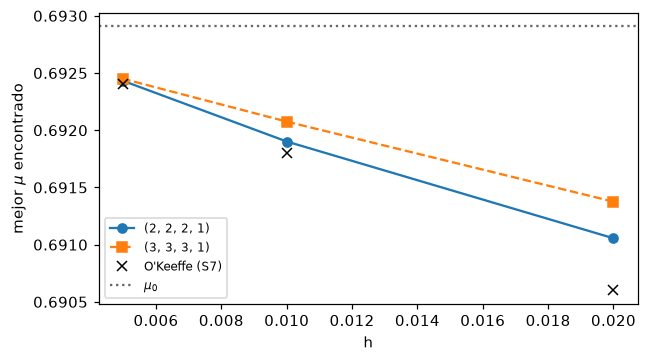

In [11]:
hs = [0.02, 0.01, 0.005]
files = {0.02: "../data/explore_splits_h0.02_s7.json",
         0.01: "../data/explore_splits_h0.01_s7_2221-3331.json",
         0.005: "../data/explore_splits_h0.005_s7_2221-3331.json"}
best = {p: [] for p in [(2, 2, 2, 1), (3, 3, 3, 1)]}
for h in hs:
    R = {tuple(r["pieces"]): r["best_mu"] for r in json.load(open(files[h]))}
    for p in best:
        best[p].append(R[p])
print(f"{'h':>6} {'S7 (2,2,2,1)':>13} {'(3,3,3,1)':>10} {'diferencia':>11} {'O’Keeffe (S7)':>14}")
paper = {0.02: 0.6906, 0.01: 0.6918, 0.005: 0.6924}
for i, h in enumerate(hs):
    a, b = best[(2, 2, 2, 1)][i], best[(3, 3, 3, 1)][i]
    print(f"{h:>6} {a:13.5f} {b:10.5f} {b - a:+11.5f} {paper[h]:14.4f}")

fig, ax = plt.subplots(figsize=(6, 3.4))
for p, mk in [((2, 2, 2, 1), "o-"), ((3, 3, 3, 1), "s--")]:
    ax.plot(hs, best[p], mk, label=str(p))
ax.plot(list(paper), list(paper.values()), "x", color="k", label="O'Keeffe (S7)")
ax.axhline(float(mu0), ls=":", color="0.4", label=r"$\mu_0$")
ax.set(xlabel="h", ylabel=r"mejor $\mu$ encontrado")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

La diferencia baja más o menos linealmente con $h$ (+0.00032, +0.00018, +0.00002), así que en el límite
$h \to 0$ partir en 3 piezas **no** mejora $\mu_0$. Es consistente con la afirmación numérica de
O'Keeffe ("allowing more pieces per cluster did not raise it"). Es un resultado negativo, pero
documentado.

## 7. Caso 0/1: blow-ups completos (la idea original)

`scripts/explore_01.py` recorre todos los grafos conexos $H$ con $k$ vértices (nauty), con
$P = A_H + I$ fija (cliques y bipartitos completos, sin densidades intermedias). Para cada uno
optimiza tamaños y fases con SLSQP desde 20 arranques.

In [12]:
for k in [5, 6, 7]:
    R = json.load(open(f"../data/explore_01_k{k}.json"))
    top = R["found"][0]["mu"] if R["found"] else float("nan")
    print(f"k = {k}: {R['n_graphs']:4d} grafos, {R['n_prefilter']:4d} pasan el prefiltro LP, "
          f"{len(R['found']):3d} con estado estricto no sync, mejor μ = {top:.4f}")

k = 5:   21 grafos,   13 pasan el prefiltro LP,   0 con estado estricto no sync, mejor μ = nan
k = 6:  112 grafos,   56 pasan el prefiltro LP,   3 con estado estricto no sync, mejor μ = 0.5998
k = 7:  853 grafos,  331 pasan el prefiltro LP,  32 con estado estricto no sync, mejor μ = 0.6162


Con grafos base chicos, los blow-ups completos no pasan de $\mu \approx 0.61$: hacen falta densidades
intermedias (las $d \to 1/2$ de Canale, las $q^* \approx 0.65$ de S7).